In [1]:
import cv2
import numpy as np
import random
import matplotlib.pyplot as plt

In [ ]:
# class BrailleGenerator:
#     def __init__(self, img_size=(1448, 1024), scale=10):
#         self.img_size = img_size
#         self.scale = scale
        
#         # Standard Marburg Medium dimensions (mm)
#         self.dot_rad = (1.5 / 2) * self.scale
#         self.px_h_dot = 2.5 * self.scale
#         self.px_v_dot = 2.5 * self.scale
#         self.px_cell_w = 6.0 * self.scale
#         self.px_line_h = 10.0 * self.scale

#     def id_to_bits(self, char_id):
#         """
#         Converts ID (0-62) to 6-bit string, then reverses it for dot mapping.
#         Example: 23 -> '010111' -> reversed -> '111010'
#         """
#         char_id = char_id - 1
#         binary = format(char_id, '06b')
#         return binary[::-1]  # Reverse the string

#     def create_soft_bump(self, radius):
#         size = int(radius * 4) 
#         if size % 2 == 0: size += 1
#         kernel = np.zeros((size, size), dtype=np.float32)
#         center = size // 2
#         for i in range(size):
#             for j in range(size):
#                 d = np.sqrt((i - center)**2 + (j - center)**2)
#                 if d < radius:
#                     kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.2
#         return kernel

#     def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.2):
#         """
#         Args:
#             allowed_chars: List of ints (0-62). If None, uses all.
#             space_prob: Probability (0-1) of a cell being a blank space.
#         """
#         if allowed_chars is None:
#             allowed_chars = list(range(63))

#         recto_h = np.zeros(self.img_size, dtype=np.float32)
#         verso_h = np.zeros(self.img_size, dtype=np.float32)
        
#         bump = self.create_soft_bump(self.dot_rad)
#         bh, bw = bump.shape
#         offset = bh // 2

#         margin = int(margin_mm * self.scale)
#         cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
#         rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

#         for r in range(rows):
#             for c in range(cols):
#                 px = margin + (c * self.px_cell_w)
#                 py = margin + (r * self.px_line_h)
                
#                 # --- Recto (Front) ---
#                 # Randomly decide if this cell is a space
#                 if random.random() > space_prob:
#                     char_id = random.choice(allowed_chars)
#                     bit_str = self.id_to_bits(char_id)
                    
#                     for i, bit in enumerate(bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(py + dy), int(px + dx)
                            
#                             # Place bump
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 recto_h[y1:y2, x1:x2] = np.maximum(recto_h[y1:y2, x1:x2], bump)

#                 # --- Verso (Back - Interpoint) ---
#                 # Offset verso by half the cell/line spacing
#                 if random.random() > space_prob:
#                     v_char_id = random.choice(allowed_chars)
#                     v_bit_str = self.id_to_bits(v_char_id)
#                     vx_base = px + (self.px_cell_w / 2)
#                     vy_base = py + (self.px_line_h / 2)

#                     for i, bit in enumerate(v_bit_str):
#                         if bit == '1':
#                             dx = (i // 3) * self.px_h_dot
#                             dy = (i % 3) * self.px_v_dot
#                             y, x = int(vy_base + dy), int(vx_base + dx)
                            
#                             y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
#                             if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
#                                 verso_h[y1:y2, x1:x2] = np.maximum(verso_h[y1:y2, x1:x2], bump)

#         # Rendering
#         total_h = (recto_h * 1.0) - (verso_h * 0.45) # Slight depth for verso
#         total_h = cv2.GaussianBlur(total_h, (3, 3), 0)

#         dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
#         dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
#         L = np.array([-0.6, -0.6, 0.8], dtype=np.float32)
#         L /= np.linalg.norm(L)
#         mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
#         nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
#         diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
#         final = 0.88 + (diffuse - 1.0) * 0.25
#         final += np.random.normal(0, 0.01, self.img_size)
        
#         return (np.clip(final, 0, 1) * 255).astype(np.uint8)

In [2]:
## Realistic ?

class BrailleGenerator:
    def __init__(self, img_size=(1448, 1024), scale=10):
        self.img_size = img_size
        self.scale = scale
        
        # Standard Marburg Medium dimensions (mm)
        self.dot_rad = (1.5 / 2) * self.scale
        self.px_h_dot = 2.5 * self.scale
        self.px_v_dot = 2.5 * self.scale
        self.px_cell_w = 6.0 * self.scale
        self.px_line_h = 10.0 * self.scale

    def id_to_bits(self, char_id):
        # Ensure ID is within valid range (0-62)
        char_id = max(0, min(62, char_id))
        binary = format(char_id, '06b')
        return binary[::-1]  # Reverse for dot mapping (1,2,3 down left, 4,5,6 down right)

    def create_soft_bump(self, radius):
        size = int(radius * 4) 
        if size % 2 == 0: size += 1
        kernel = np.zeros((size, size), dtype=np.float32)
        center = size // 2
        for i in range(size):
            for j in range(size):
                d = np.sqrt((i - center)**2 + (j - center)**2)
                if d < radius:
                    kernel[i,j] = np.cos(min(1, d/radius) * (np.pi/2))**1.4 # Slightly steeper for better shadows
        return kernel

    def apply_vignette(self, img, strength=0.2):
        """Adds natural lighting falloff to the corners."""
        rows, cols = img.shape
        kernel_x = cv2.getGaussianKernel(cols, cols/2)
        kernel_y = cv2.getGaussianKernel(rows, rows/2)
        vignette = kernel_y * kernel_x.T
        vignette = vignette / vignette.max()
        return img * ((1 - strength) + strength * vignette)

    def generate_paper_texture(self):
        """Creates realistic paper texture using combined noise frequencies."""
        # Base ambient color
        texture = np.full(self.img_size, 0.99, dtype=np.float32)
        
        # 1. High-frequency grain (micro-texture)
        grain = np.random.normal(0, 0.035, self.img_size)
        
        # 2. Low-frequency 'clouds' (surface variations)
        small_noise = np.random.normal(0, 0.08, (self.img_size[0]//20, self.img_size[1]//20))
        clouds = cv2.resize(small_noise, (self.img_size[1], self.img_size[0]), interpolation=cv2.INTER_CUBIC)
        clouds = cv2.GaussianBlur(clouds, (15, 15), 0)
        
        return texture + grain + (clouds * 0.001)

    def apply_perspective_skew(self, img, max_skew_px=60):
        """Applies a prominent 3D perspective skew to the final image."""
        h, w = img.shape
        
        # Scale the skew factor based on the PPM (scale)
        skew_factor = max_skew_px * (self.scale / 10)
        
        # Define source points (original corners)
        src_pts = np.float32([[0, 0], [w-1, 0], [0, h-1], [w-1, h-1]])
        
        # Generate random aggressive shifts for a 3D effect
        # We compress one side and stretch the other to simulate camera tilt
        top_left_x = random.uniform(0, skew_factor)
        top_right_x = random.uniform(-skew_factor, 0)
        bottom_left_x = random.uniform(-skew_factor, 0)
        bottom_right_x = random.uniform(0, skew_factor)
        
        top_y_tilt = random.uniform(0, skew_factor * 0.5)
        bottom_y_tilt = random.uniform(-skew_factor * 0.5, 0)

        dst_pts = np.float32([
            [0 + top_left_x, 0 + top_y_tilt],           # Top Left
            [w-1 + top_right_x, 0 + top_y_tilt],        # Top Right
            [0 + bottom_left_x, h-1 + bottom_y_tilt],   # Bottom Left
            [w-1 + bottom_right_x, h-1 + bottom_y_tilt] # Bottom Right
        ])
        
        # Calculate transformation matrix
        M = cv2.getPerspectiveTransform(src_pts, dst_pts)
        
        # Apply warp with BORDER_REPLICATE to keep the paper texture consistent at edges
        return cv2.warpPerspective(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    def generate_page(self, allowed_chars=None, margin_mm=20, space_prob=0.15, apply_skew=True):
        if allowed_chars is None:
            allowed_chars = list(range(63))

        recto_h = np.zeros(self.img_size, dtype=np.float32)
        verso_h = np.zeros(self.img_size, dtype=np.float32)
        
        bump = self.create_soft_bump(self.dot_rad)
        bh, bw = bump.shape
        offset = bh // 2

        margin = int(margin_mm * self.scale)
        cols = int((self.img_size[1] - (2 * margin)) // self.px_cell_w)
        rows = int((self.img_size[0] - (2 * margin)) // self.px_line_h)

        for r in range(rows):
            for c in range(cols):
                px = margin + (c * self.px_cell_w)
                py = margin + (r * self.px_line_h)
                
                # --- Recto (Front) ---
                if random.random() > space_prob:
                    char_id = random.choice(allowed_chars)
                    bit_str = self.id_to_bits(char_id)
                    
                    for i, bit in enumerate(bit_str):
                        if bit == '1':
                            # Subtle randomization of dot position (0.5mm max)
                            jitter_x = random.uniform(-0.05, 0.05) * self.scale
                            jitter_y = random.uniform(-0.05, 0.05) * self.scale

                            dx = (i // 3) * self.px_h_dot + jitter_x
                            dy = (i % 3) * self.px_v_dot + jitter_y
                            y, x = int(py + dy), int(px + dx)
                            
                            y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
                                recto_h[y1:y2, x1:x2] = np.maximum(recto_h[y1:y2, x1:x2], bump)

                # --- Verso (Back - Interpoint) ---
                if random.random() > space_prob:
                    v_char_id = random.choice(allowed_chars)
                    v_bit_str = self.id_to_bits(v_char_id)
                    vx_base = px + (self.px_cell_w / 2)
                    vy_base = py + (self.px_line_h / 2)

                    for i, bit in enumerate(v_bit_str):
                        if bit == '1':
                            dx = (i // 3) * self.px_h_dot
                            dy = (i % 3) * self.px_v_dot
                            y, x = int(vy_base + dy), int(vx_base + dx)
                            
                            y1, y2, x1, x2 = y-offset, y+offset+1, x-offset, x+offset+1
                            if 0 <= y1 and y2 < self.img_size[0] and 0 <= x1 and x2 < self.img_size[1]:
                                verso_h[y1:y2, x1:x2] = np.maximum(verso_h[y1:y2, x1:x2], bump)

        # Rendering
        total_h = (recto_h * 1.0) - (verso_h * 0.40) # Slightly shallower verso
        total_h = cv2.GaussianBlur(total_h, (5, 5), 0) # Smooth normals

        dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
        dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
        
        L = np.array([-0.7, -0.7, 1.0], dtype=np.float32) # Stronger top-left light
        L /= np.linalg.norm(L)
        mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
        nx, ny, nz = -dzdx/mag, -dzdy/mag, 1/mag
        
        diffuse = (nx * L[0] + ny * L[1] + nz * L[2])
        shading = (diffuse - 1.0) * 0.3 # Increased shading strength
        
        # Combine everything
        final = self.generate_paper_texture() + shading
        final = self.apply_vignette(final, strength=0.25)
        
        if apply_skew:
            final = self.apply_perspective_skew(final, max_skew_px=20 * (self.scale/10))

        return (np.clip(final, 0, 1) * 255).astype(np.uint8)

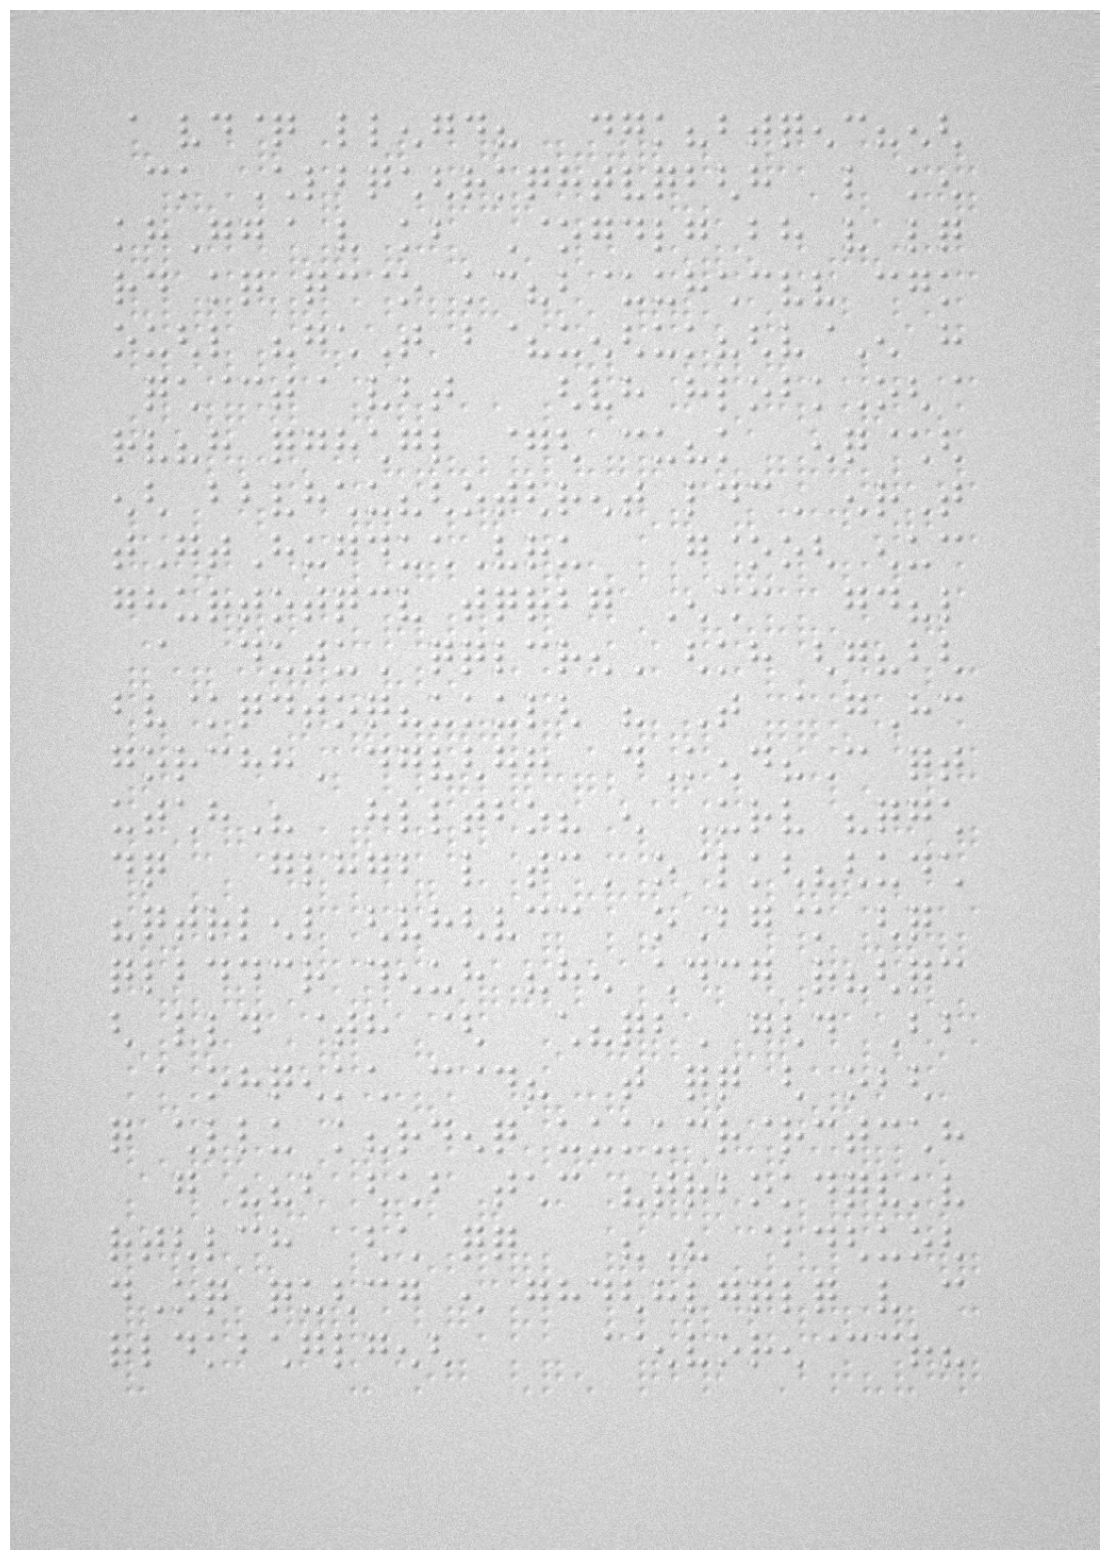

In [ ]:
gen = BrailleGenerator(scale=5)
allowed_chars=[3, 7, 8, 9, 5, 19, 21, 23, 25, 27, 30, 31, 32, 33, 34, 35, 37, 38, 39]
img = gen.generate_page(allowed_chars=allowed_chars)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# plt.figure(figsize=(40, 20))
plt.axis("off")
plt.imshow(img)
plt.savefig("test-synthesized-braille.jpg")
plt.show()